In [2]:
# ============================================================
# Sel 1: Mount Google Drive & Setup Environment
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers tokenizers scikit-learn pandas matplotlib seaborn

import os
import time
import gc
import re
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch version : {torch.__version__}")
print(f"Device aktif    : {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch version : 2.11.0+cu130
Device aktif    : cuda (NVIDIA A100-SXM4-40GB)


In [5]:
# ============================================================
# Sel 2: Deklarasi Path & Verifikasi Artefak Model Tersimpan
# ============================================================
PROJECT_DIR = '/content/drive/MyDrive/Skripsi'

# Path Model & Tokenizer yang sudah disimpan dari Skripsi.ipynb
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
DISTILBERT_SAVE_PATH = os.path.join(MODELS_DIR, 'distilbert_phishing')
ROBERTA_SAVE_PATH = os.path.join(MODELS_DIR, 'roberta_phishing')

# Path Dataset Eksternal
EXTERNAL_CSV = os.path.join(PROJECT_DIR, 'data', 'external', 'phishing_url_dataset_unique.csv')

# Path Output Hasil Evaluasi Eksternal
EXT_RESULTS_DIR = os.path.join(PROJECT_DIR, 'results', 'external_evaluation')
os.makedirs(EXT_RESULTS_DIR, exist_ok=True)

EXT_RESULTS_CSV = os.path.join(EXT_RESULTS_DIR, 'hasil_evaluasi_eksternal_distilbert_vs_roberta.csv')
LOG_FILE = os.path.join(PROJECT_DIR, 'SKRIPSI_LOG.md')

MAX_LENGTH = 128
BATCH_SIZE = 64  # Inferensi murni tanpa gradien aman menggunakan batch 64

# Verifikasi kelengkapan artefak sebelum lanjut
for name, path in [('DistilBERT', DISTILBERT_SAVE_PATH), ('RoBERTa', ROBERTA_SAVE_PATH)]:
    assert os.path.exists(path), f"❌ Folder {name} tidak ditemukan di: {path}"
    print(f"✅ Folder {name} siap: {os.listdir(path)}")

assert os.path.exists(EXTERNAL_CSV), f"❌ File dataset eksternal tidak ditemukan di: {EXTERNAL_CSV}"
print(f"✅ Dataset Eksternal ditemukan: {EXTERNAL_CSV}")

✅ Folder DistilBERT siap: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']
✅ Folder RoBERTa siap: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']
✅ Dataset Eksternal ditemukan: /content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv


In [6]:
# ============================================================
# Sel 3: Load Dataset Eksternal & Preprocessing URL
# ============================================================
raw_ext_df = pd.read_csv(EXTERNAL_CSV)
print(f"Dataset eksternal asli: {len(raw_ext_df):,} baris | Kolom: {raw_ext_df.columns.tolist()}")
print("\n5 baris pertama dataset eksternal:")
print(raw_ext_df.head(5))

# --- 1. Auto-Detect Nama Kolom URL dan Label ---
col_map = {c.lower().strip(): c for c in raw_ext_df.columns}
url_col = next((col_map[k] for k in ['url', 'urls', 'link', 'domain', 'website', 'text'] if k in col_map), raw_ext_df.columns[0])
label_col = next((col_map[k] for k in ['label', 'labels', 'status', 'type', 'class', 'target', 'result', 'phishing'] if k in col_map), raw_ext_df.columns[1])

print(f"\nKolom terdeteksi -> Kolom URL: '{url_col}' | Kolom Label: '{label_col}'")

ext_df = raw_ext_df[[url_col, label_col]].copy()
ext_df.columns = ['url', 'label']
ext_df = ext_df.dropna(subset=['url', 'label']).reset_index(drop=True)

# --- 2. Standarisasi Label ke Biner (0 = Benign, 1 = Phishing) ---
if ext_df['label'].dtype == object or str(ext_df['label'].dtype) == 'category':
    label_str = ext_df['label'].astype(str).str.lower().str.strip()
    label_mapping = {
        'benign': 0, 'legitimate': 0, 'good': 0, 'safe': 0, 'normal': 0, '0': 0, 'false': 0, '-1': 0,
        'phishing': 1, 'malicious': 1, 'bad': 1, 'unsafe': 1, 'defacement': 1, 'malware': 1, 'spam': 1, '1': 1, 'true': 1
    }
    ext_df['label'] = label_str.map(label_mapping)
    ext_df = ext_df.dropna(subset=['label'])

ext_df['label'] = ext_df['label'].astype(int)
ext_df = ext_df[ext_df['label'].isin([0, 1])].reset_index(drop=True)

print(f"Total data bersih siap uji: {len(ext_df):,} sampel")
print(f"Distribusi kelas:\n{ext_df['label'].value_counts().rename({0: '0 (Benign)', 1: '1 (Phishing)'}).to_string()}")

# --- 3. Fungsi Preprocessing URL (IDENTIK dengan Sel 4 Skripsi.ipynb) ---
def preprocess_url(url):
    if not isinstance(url, str):
        return ''
    url = url.lower().strip()
    try:
        if '://' in url:
            protocol, rest = url.split('://', 1)
            if '/' in rest:
                hostname, path = rest.split('/', 1)
                path = '/' + path
            else:
                hostname = rest
                path = ''
            try:
                hostname = hostname.encode('idna').decode('ascii')
            except (UnicodeError, UnicodeDecodeError):
                pass
            url = protocol + '://' + hostname + path
    except Exception:
        pass

    url = url.replace('://', ' :// ')
    url = url.replace('/', ' / ')
    url = url.replace('?', ' ? ')
    url = url.replace('=', ' = ')
    url = url.replace('&', ' & ')
    url = url.replace('.', ' . ')
    url = url.replace('-', ' - ')
    url = re.sub(r'\s+', ' ', url).strip()
    return url

print("\nMenjalankan preprocessing URL pada dataset eksternal...")
ext_df['raw_url'] = ext_df['url']
ext_df['url'] = ext_df['url'].apply(preprocess_url)
print("✅ Preprocessing selesai.")

Dataset eksternal asli: 48,812 baris | Kolom: ['url', 'label', 'source']

5 baris pertama dataset eksternal:
                                                 url  label   source
0                  http://110.37.26.193:54956/bin.sh      1  urlhaus
1           https://sentry5.obor1shwron8.ru/4ylkytvt      1  urlhaus
2               https://d6gu.ripple-cask.ru/jid43vpd      1  urlhaus
3  http://130.12.180.34/596a96cc7bf9108cd896f33c4...      1  urlhaus
4                             https://bronze.systems      0   tranco

Kolom terdeteksi -> Kolom URL: 'url' | Kolom Label: 'label'
Total data bersih siap uji: 48,812 sampel
Distribusi kelas:
label
1 (Phishing)    24406
0 (Benign)      24406

Menjalankan preprocessing URL pada dataset eksternal...
✅ Preprocessing selesai.


✅ Tokenizer berhasil dimuat dari: /content/drive/MyDrive/Skripsi/models/distilbert_phishing
   Ukuran kosakata: 30,372 token
   External DataLoader siap: 763 batches (Batch Size=64)


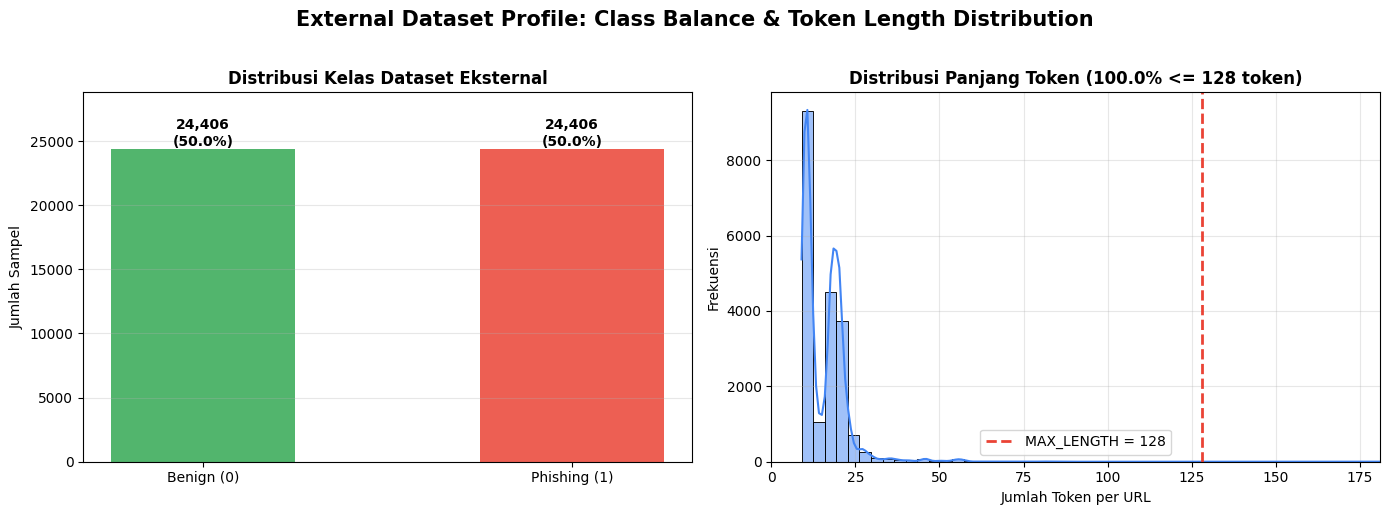

📊 Grafik 1 disimpan ke: /content/drive/MyDrive/Skripsi/results/external_evaluation/01_external_data_profile.png


In [7]:
# ============================================================
# Sel 4: Load Tokenizer Tersimpan, DataLoader, & Grafik 1
# ============================================================
from transformers import PreTrainedTokenizerFast, AutoTokenizer
from torch.utils.data import Dataset, DataLoader

# Panggil langsung tokenizer.json yang sudah tersimpan di folder model
tokenizer = PreTrainedTokenizerFast.from_pretrained(DISTILBERT_SAVE_PATH)
print(f"✅ Tokenizer berhasil dimuat dari: {DISTILBERT_SAVE_PATH}")
print(f"   Ukuran kosakata: {len(tokenizer):,} token")

class ExternalURLDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.urls = dataframe['url'].values
        self.labels = dataframe['label'].values
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.urls)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.urls[idx]),
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(int(self.labels[idx]), dtype=torch.long)
        }

ext_dataset = ExternalURLDataset(ext_df, tokenizer, MAX_LENGTH)
ext_loader = DataLoader(ext_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"   External DataLoader siap: {len(ext_loader):,} batches (Batch Size={BATCH_SIZE})")

# --- GRAFIK 1: Distribusi Kelas & Panjang Token URL Eksternal ---
sample_size = min(20000, len(ext_df))
sample_df = ext_df.sample(n=sample_size, random_state=42)
token_lengths = [len(tokenizer.encode(u, truncation=False)) for u in sample_df['url']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('External Dataset Profile: Class Balance & Token Length Distribution', fontsize=15, fontweight='bold', y=1.02)

# Plot A: Komposisi Kelas
class_counts = ext_df['label'].value_counts().sort_index()
bars = axes[0].bar(['Benign (0)', 'Phishing (1)'], class_counts.values, color=['#34A853', '#EA4335'], alpha=0.85, width=0.5)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + (max(class_counts)*0.01), f"{h:,}\n({h/len(ext_df)*100:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Distribusi Kelas Dataset Eksternal', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
axes[0].set_ylim(0, max(class_counts)*1.18)
axes[0].grid(axis='y', alpha=0.3)

# Plot B: Distribusi Panjang Token
sns.histplot(token_lengths, bins=50, kde=True, color='#4285F4', ax=axes[1])
axes[1].axvline(MAX_LENGTH, color='#EA4335', linestyle='--', linewidth=2, label=f'MAX_LENGTH = {MAX_LENGTH}')
pct_under_max = np.mean(np.array(token_lengths) <= MAX_LENGTH) * 100
axes[1].set_title(f'Distribusi Panjang Token ({pct_under_max:.1f}% <= {MAX_LENGTH} token)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Token per URL')
axes[1].set_ylabel('Frekuensi')
axes[1].set_xlim(0, min(300, max(token_lengths)))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
g1_path = os.path.join(EXT_RESULTS_DIR, '01_external_data_profile.png')
plt.savefig(g1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"📊 Grafik 1 disimpan ke: {g1_path}")

In [9]:
# ============================================================
# Sel 5: Fungsi Modular Evaluasi Eksternal & Benchmark
# ============================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

def evaluate_external_model(model, dataloader, device, model_label):
    model.to(device)
    model.eval()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    all_preds, all_labels, all_probs = [], [], []
    total_samples = 0

    # Warm-up GPU
    with torch.no_grad():
        for batch in dataloader:
            _ = model(
                input_ids=batch['input_ids'].to(device),
                attention_mask=batch['attention_mask'].to(device)
            )
            break

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels']

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=-1)
            preds = torch.argmax(outputs.logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
            total_samples += len(labels)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    total_time = time.perf_counter() - start_time
    peak_vram = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0

    y_true = np.array(all_labels)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)

    res = {
        'model': model_label,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='binary', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='binary', zero_division=0),
        'f1_score': f1_score(y_true, y_pred, average='binary', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
        'confusion_matrix': confusion_matrix(y_true, y_pred),
        'total_inference_time_s': total_time,
        'latency_per_sample_ms': (total_time / total_samples) * 1000,
        'throughput_samples_per_s': total_samples / total_time,
        'peak_vram_inference_gb': peak_vram,
        'total_params': sum(p.numel() for p in model.parameters()),
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob
    }

    print(f"\n{'='*60}")
    print(f"  HASIL EVALUASI EKSTERNAL: {model_label}")
    print(f"{'='*60}")
    print(f"  Accuracy   : {res['accuracy']:.6f} ({res['accuracy']*100:.2f}%)")
    print(f"  Precision  : {res['precision']:.6f}")
    print(f"  Recall     : {res['recall']:.6f}")
    print(f"  F1-Score   : {res['f1_score']:.6f}")
    print(f"  F1-Macro   : {res['f1_macro']:.6f}")
    print(f"  ROC-AUC    : {res['roc_auc']:.6f}")
    print(f"  PR-AUC     : {res['pr_auc']:.6f}")
    print(f"  Latency    : {res['latency_per_sample_ms']:.4f} ms/sample")
    print(f"  Throughput : {res['throughput_samples_per_s']:.2f} samples/s")
    print(f"  Peak VRAM  : {res['peak_vram_inference_gb']:.3f} GB")
    print(f"  Confusion Matrix:\n{res['confusion_matrix']}")
    return res

In [10]:
# ============================================================
# Sel 6: Panggil & Evaluasi DistilBERT dari Google Drive
# ============================================================
from transformers import DistilBertForSequenceClassification

print(f"Memuat model DistilBERT dari: {DISTILBERT_SAVE_PATH}...")
distil_model = DistilBertForSequenceClassification.from_pretrained(DISTILBERT_SAVE_PATH)

ext_distil_results = evaluate_external_model(
    model=distil_model,
    dataloader=ext_loader,
    device=DEVICE,
    model_label='DistilBERT-base'
)

del distil_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("✅ Evaluasi DistilBERT selesai & memori GPU dibersihkan.")

Memuat model DistilBERT dari: /content/drive/MyDrive/Skripsi/models/distilbert_phishing...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


  HASIL EVALUASI EKSTERNAL: DistilBERT-base
  Accuracy   : 0.728960 (72.90%)
  Precision  : 0.662887
  Recall     : 0.931779
  F1-Score   : 0.774663
  F1-Macro   : 0.717332
  ROC-AUC    : 0.918836
  PR-AUC     : 0.937182
  Latency    : 0.7100 ms/sample
  Throughput : 1408.53 samples/s
  Peak VRAM  : 0.517 GB
  Confusion Matrix:
[[12841 11565]
 [ 1665 22741]]
✅ Evaluasi DistilBERT selesai & memori GPU dibersihkan.


In [11]:
# ============================================================
# Sel 7: Panggil & Evaluasi RoBERTa dari Google Drive
# ============================================================
from transformers import RobertaForSequenceClassification

print(f"Memuat model RoBERTa dari: {ROBERTA_SAVE_PATH}...")
roberta_model = RobertaForSequenceClassification.from_pretrained(ROBERTA_SAVE_PATH)

ext_roberta_results = evaluate_external_model(
    model=roberta_model,
    dataloader=ext_loader,
    device=DEVICE,
    model_label='RoBERTa-base'
)

del roberta_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("✅ Evaluasi RoBERTa selesai & memori GPU dibersihkan.")

Memuat model RoBERTa dari: /content/drive/MyDrive/Skripsi/models/roberta_phishing...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


  HASIL EVALUASI EKSTERNAL: RoBERTa-base
  Accuracy   : 0.685631 (68.56%)
  Precision  : 0.634313
  Recall     : 0.876670
  F1-Score   : 0.736054
  F1-Macro   : 0.673723
  ROC-AUC    : 0.875380
  PR-AUC     : 0.915306
  Latency    : 1.3971 ms/sample
  Throughput : 715.79 samples/s
  Peak VRAM  : 0.677 GB
  Confusion Matrix:
[[12071 12335]
 [ 3010 21396]]
✅ Evaluasi RoBERTa selesai & memori GPU dibersihkan.


  TABEL KOMPARASI EVALUASI DATASET EKSTERNAL
Model                   DistilBERT-base  RoBERTa-base
Accuracy                   7.289601e-01  6.856306e-01
Precision                  6.628870e-01  6.343127e-01
Recall                     9.317791e-01  8.766697e-01
F1-Score (Binary)          7.746628e-01  7.360545e-01
F1-Score (Macro)           7.173324e-01  6.737228e-01
ROC-AUC                    9.188362e-01  8.753800e-01
PR-AUC                     9.371820e-01  9.153063e-01
Inference Time (s)         3.465457e+01  6.819287e+01
Latency (ms/sample)        7.099600e-01  1.397051e+00
Throughput (samples/s)     1.408530e+03  7.157933e+02
Peak VRAM (GB)             5.173144e-01  6.766028e-01
Total Parameters           6.683981e+07  1.093693e+08

✅ CSV disimpan ke: /content/drive/MyDrive/Skripsi/results/external_evaluation/hasil_evaluasi_eksternal_distilbert_vs_roberta.csv


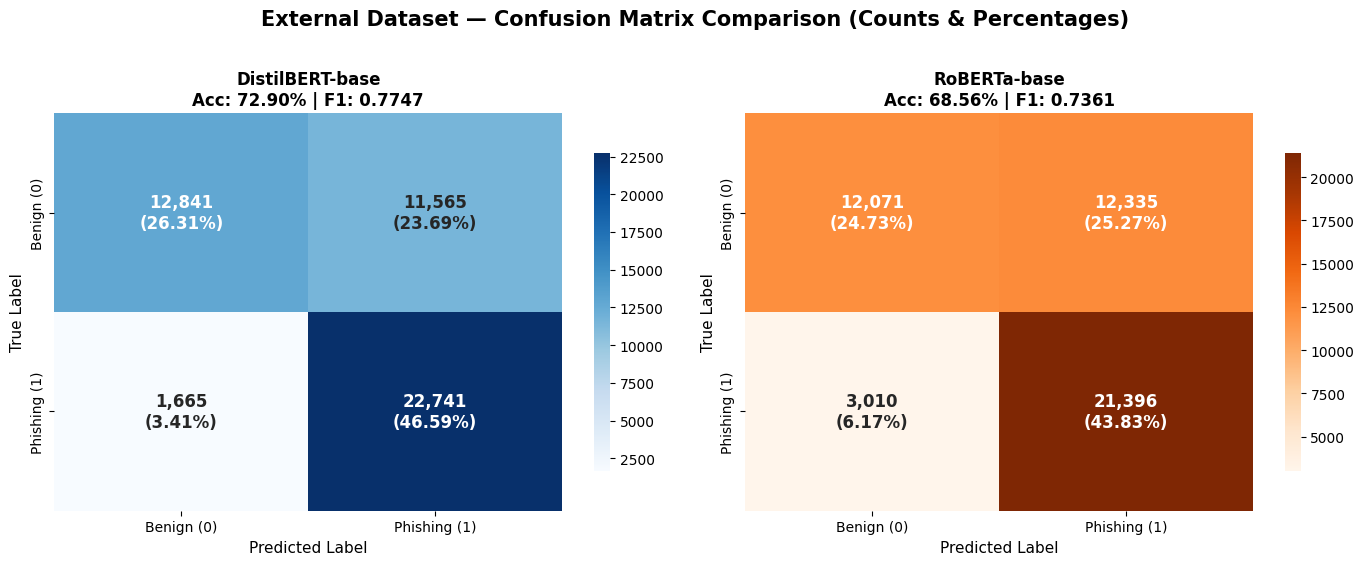

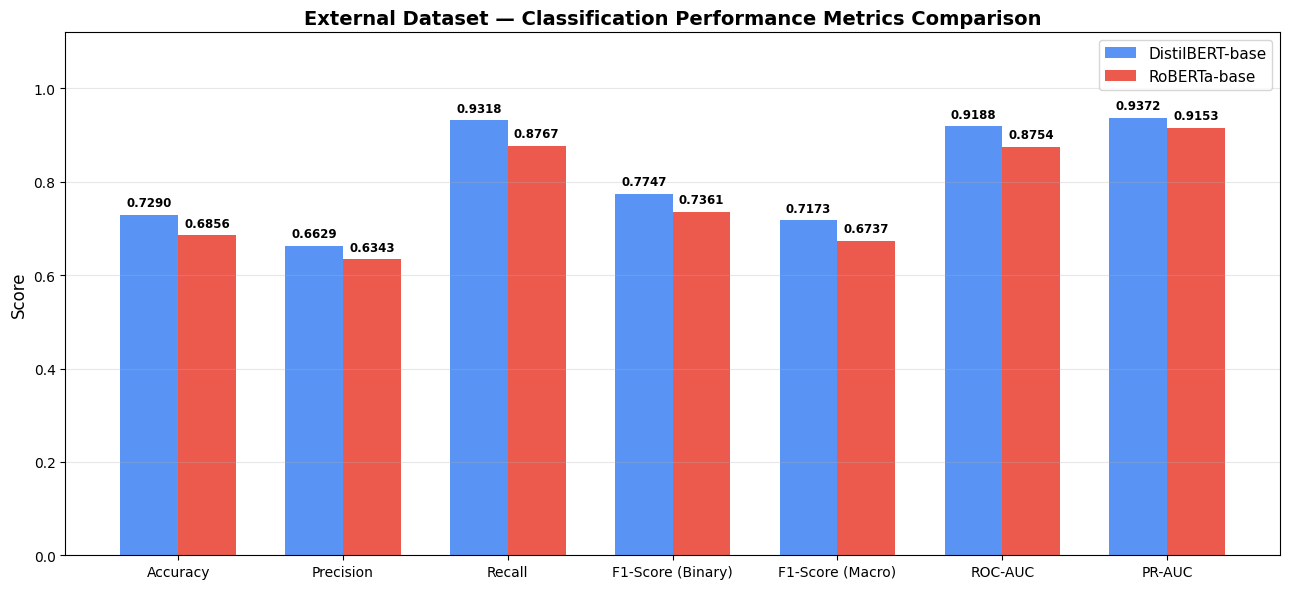

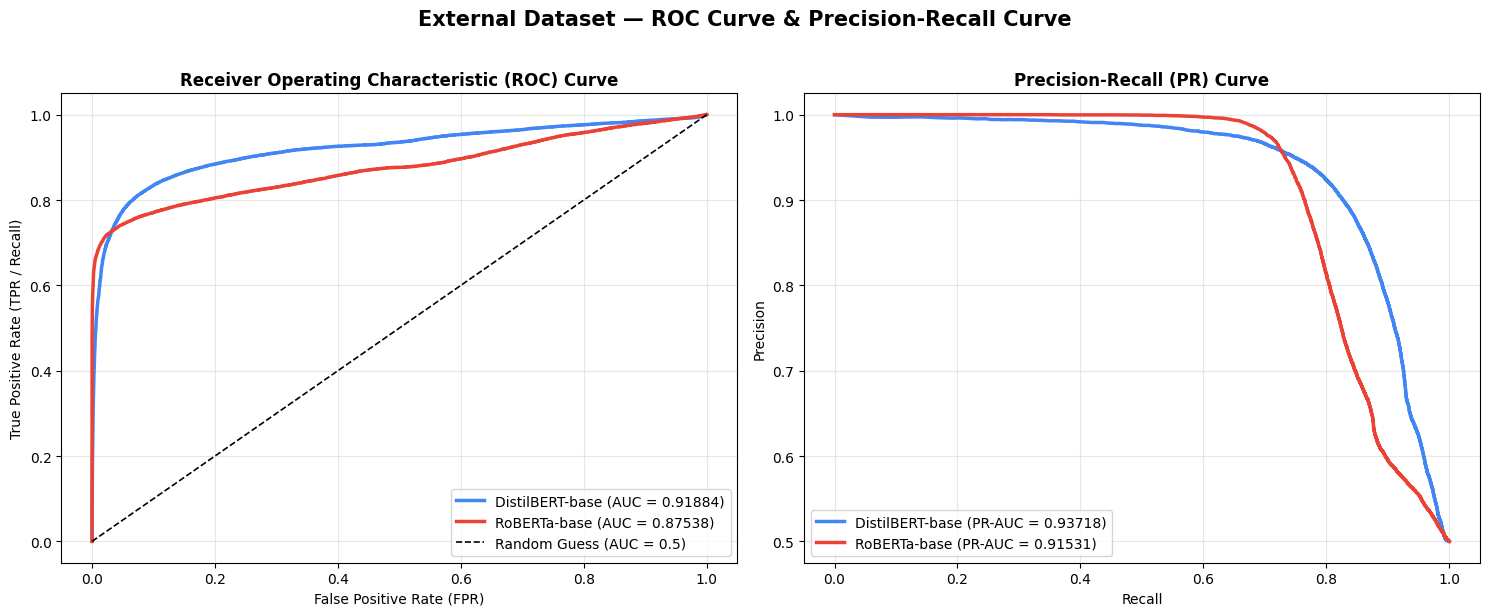

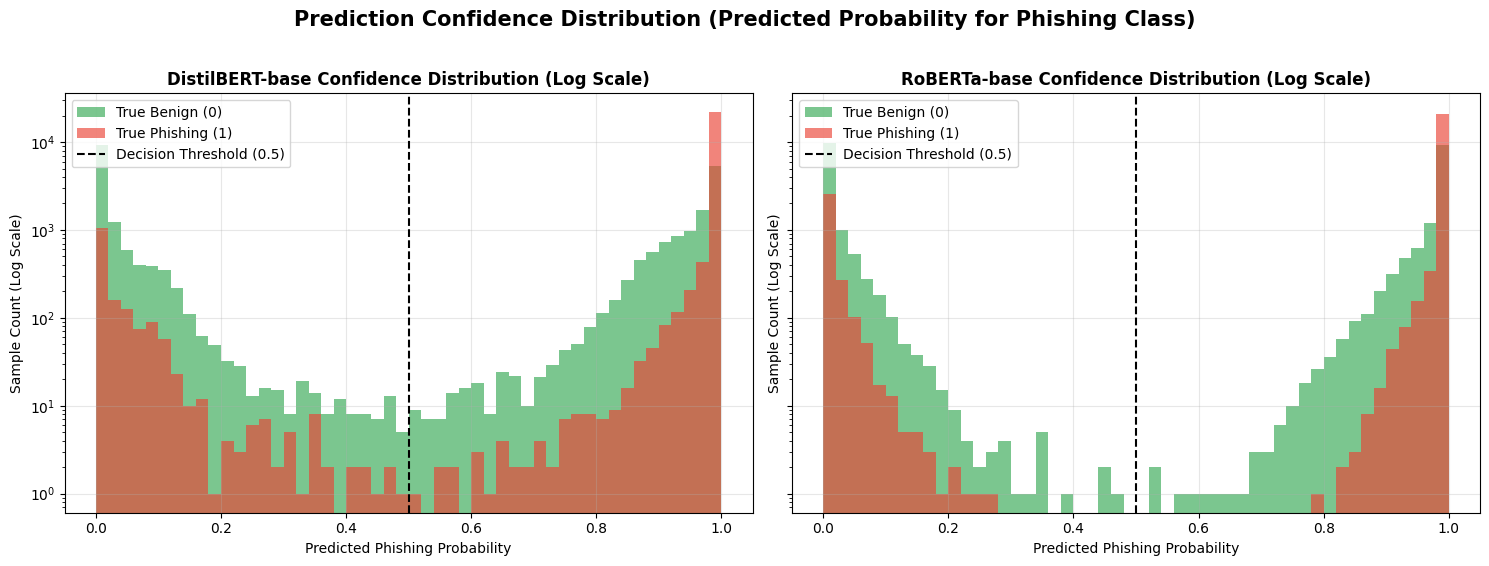

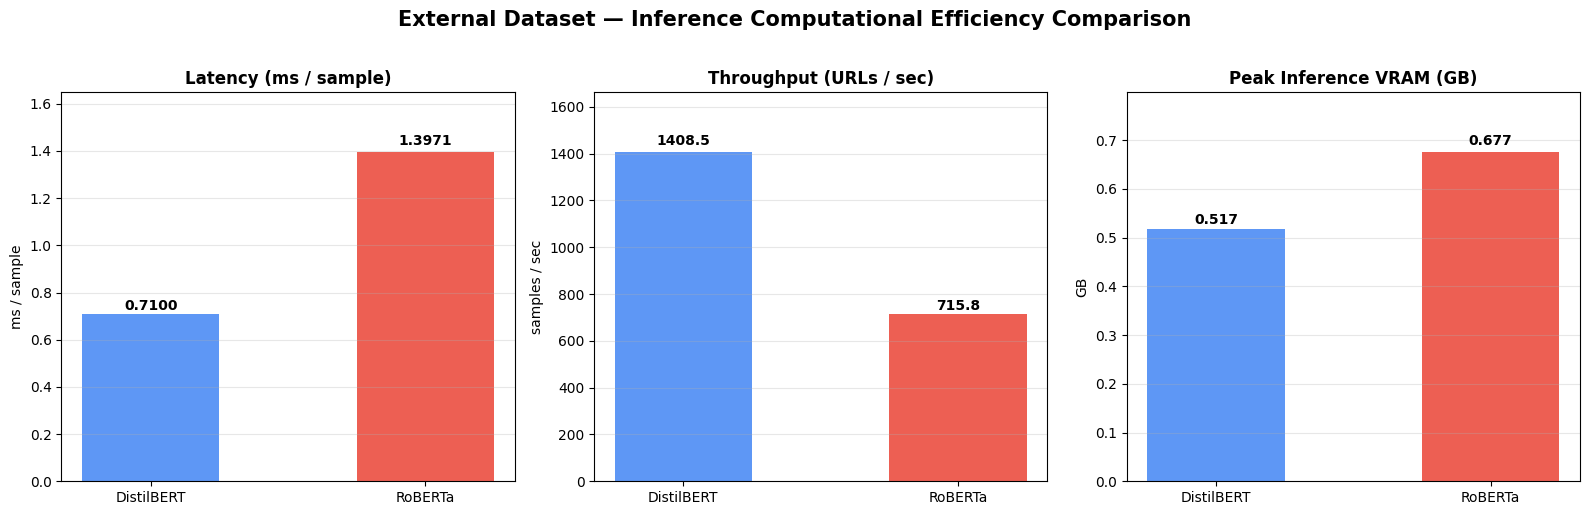

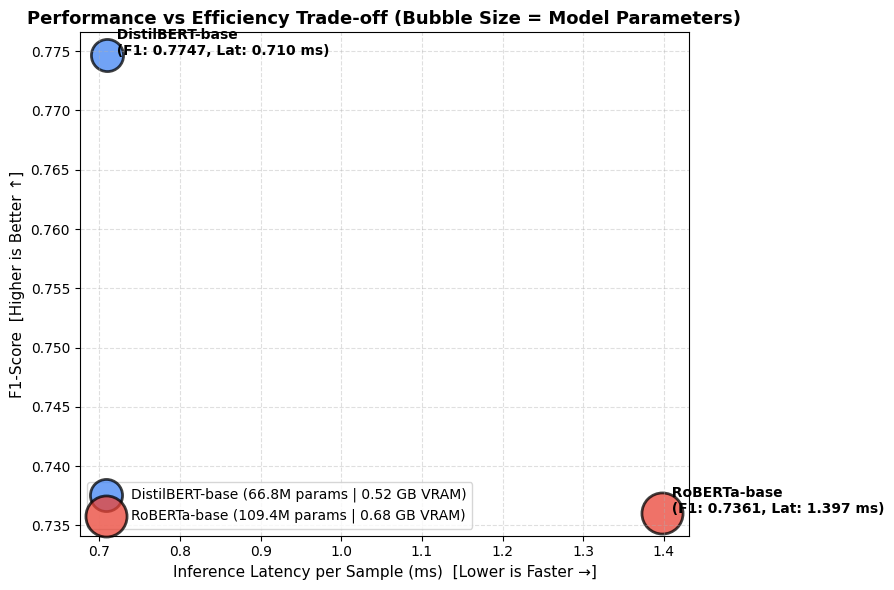


✅ Seluruh 8 grafik evaluasi eksternal berhasil disimpan di folder: /content/drive/MyDrive/Skripsi/results/external_evaluation


In [12]:
# ============================================================
# Sel 8: Visualisasi Lengkap (Grafik 2 - 8) & Ekspor CSV
# ============================================================

# 1. Simpan Tabel Komparasi ke CSV
summary_rows = []
for r in [ext_distil_results, ext_roberta_results]:
    summary_rows.append({
        'Model': r['model'],
        'Accuracy': r['accuracy'],
        'Precision': r['precision'],
        'Recall': r['recall'],
        'F1-Score (Binary)': r['f1_score'],
        'F1-Score (Macro)': r['f1_macro'],
        'ROC-AUC': r['roc_auc'],
        'PR-AUC': r['pr_auc'],
        'Inference Time (s)': r['total_inference_time_s'],
        'Latency (ms/sample)': r['latency_per_sample_ms'],
        'Throughput (samples/s)': r['throughput_samples_per_s'],
        'Peak VRAM (GB)': r['peak_vram_inference_gb'],
        'Total Parameters': r['total_params']
    })

ext_comp_df = pd.DataFrame(summary_rows)
ext_comp_df.to_csv(EXT_RESULTS_CSV, index=False)
print("="*80)
print("  TABEL KOMPARASI EVALUASI DATASET EKSTERNAL")
print("="*80)
print(ext_comp_df.set_index('Model').T.to_string())
print(f"\n✅ CSV disimpan ke: {EXT_RESULTS_CSV}")

# ------------------------------------------------------------------
# GRAFIK 2: Confusion Matrix (Jumlah Absolut + Persentase)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle('External Dataset — Confusion Matrix Comparison (Counts & Percentages)', fontsize=15, fontweight='bold', y=1.02)
labels_names = ['Benign (0)', 'Phishing (1)']

for ax, res, cmap in zip(axes, [ext_distil_results, ext_roberta_results], ['Blues', 'Oranges']):
    cm = res['confusion_matrix']
    cm_pct = cm / cm.sum() * 100
    annot_text = np.array([[f"{cnt:,}\n({pct:.2f}%)" for cnt, pct in zip(row_c, row_p)] for row_c, row_p in zip(cm, cm_pct)])
    sns.heatmap(cm, annot=annot_text, fmt='', cmap=cmap, xticklabels=labels_names, yticklabels=labels_names,
                ax=ax, cbar_kws={'shrink': 0.8}, annot_kws={'size': 12, 'fontweight': 'bold'})
    ax.set_title(f"{res['model']}\nAcc: {res['accuracy']*100:.2f}% | F1: {res['f1_score']:.4f}", fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

plt.tight_layout()
g2_path = os.path.join(EXT_RESULTS_DIR, '02_external_confusion_matrices.png')
plt.savefig(g2_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# GRAFIK 3: Grouped Bar Chart Metrik Klasifikasi
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6))
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score (Binary)', 'F1-Score (Macro)', 'ROC-AUC', 'PR-AUC']
x = np.arange(len(metrics_cols))
w = 0.35

d_vals = [ext_comp_df.loc[0, m] for m in metrics_cols]
r_vals = [ext_comp_df.loc[1, m] for m in metrics_cols]

b1 = ax.bar(x - w/2, d_vals, w, label='DistilBERT-base', color='#4285F4', alpha=0.88)
b2 = ax.bar(x + w/2, r_vals, w, label='RoBERTa-base', color='#EA4335', alpha=0.88)

for group in [b1, b2]:
    for bar in group:
        h = bar.get_height()
        ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4),
                    textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('External Dataset — Classification Performance Metrics Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_cols, fontsize=10)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
g3_path = os.path.join(EXT_RESULTS_DIR, '03_external_performance_bars.png')
plt.savefig(g3_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# GRAFIK 4 & 5: Kurva ROC dan Kurva Precision-Recall Berdampingan
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('External Dataset — ROC Curve & Precision-Recall Curve', fontsize=15, fontweight='bold', y=1.02)

for res, color in [(ext_distil_results, '#4285F4'), (ext_roberta_results, '#EA4335')]:
    fpr, tpr, _ = roc_curve(res['y_true'], res['y_prob'])
    axes[0].plot(fpr, tpr, color=color, lw=2.5, label=f"{res['model']} (AUC = {res['roc_auc']:.5f})")

    prec_c, rec_c, _ = precision_recall_curve(res['y_true'], res['y_prob'])
    axes[1].plot(rec_c, prec_c, color=color, lw=2.5, label=f"{res['model']} (PR-AUC = {res['pr_auc']:.5f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess (AUC = 0.5)')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR / Recall)')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)

plt.tight_layout()
g45_path = os.path.join(EXT_RESULTS_DIR, '04_05_external_roc_and_pr_curves.png')
plt.savefig(g45_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# GRAFIK 6: Distribusi Skor Probabilitas Prediksi (Confidence Distribution)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
fig.suptitle('Prediction Confidence Distribution (Predicted Probability for Phishing Class)', fontsize=15, fontweight='bold', y=1.02)

for ax, res in zip(axes, [ext_distil_results, ext_roberta_results]):
    benign_probs = res['y_prob'][res['y_true'] == 0]
    phish_probs = res['y_prob'][res['y_true'] == 1]
    ax.hist(benign_probs, bins=50, alpha=0.65, color='#34A853', label='True Benign (0)', log=True)
    ax.hist(phish_probs, bins=50, alpha=0.65, color='#EA4335', label='True Phishing (1)', log=True)
    ax.axvline(0.5, color='black', linestyle='--', lw=1.5, label='Decision Threshold (0.5)')
    ax.set_title(f"{res['model']} Confidence Distribution (Log Scale)", fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Phishing Probability')
    ax.set_ylabel('Sample Count (Log Scale)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
g6_path = os.path.join(EXT_RESULTS_DIR, '06_external_confidence_distribution.png')
plt.savefig(g6_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# GRAFIK 7: Bar Chart Efisiensi Inferensi (Latency, Throughput, VRAM)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('External Dataset — Inference Computational Efficiency Comparison', fontsize=15, fontweight='bold', y=1.02)

models_short = ['DistilBERT', 'RoBERTa']
colors = ['#4285F4', '#EA4335']

eff_metrics = [
    ('latency_per_sample_ms', 'Latency (ms / sample)', 'ms / sample', '{:.4f}'),
    ('throughput_samples_per_s', 'Throughput (URLs / sec)', 'samples / sec', '{:.1f}'),
    ('peak_vram_inference_gb', 'Peak Inference VRAM (GB)', 'GB', '{:.3f}')
]

for ax, (key, title, ylabel, fmt_str) in zip(axes, eff_metrics):
    vals = [ext_distil_results[key], ext_roberta_results[key]]
    bars = ax.bar(models_short, vals, color=colors, alpha=0.85, width=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.02, fmt_str.format(v), ha='center', fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals)*1.18)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
g7_path = os.path.join(EXT_RESULTS_DIR, '07_external_efficiency_bars.png')
plt.savefig(g7_path, dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# GRAFIK 8: Bubble Plot Trade-off (Latency vs F1-Score vs Parameter Size)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
for res, color in [(ext_distil_results, '#4285F4'), (ext_roberta_results, '#EA4335')]:
    size_bubble = (res['total_params'] / 1e6) * 8
    ax.scatter(res['latency_per_sample_ms'], res['f1_score'], s=size_bubble, color=color, alpha=0.75, edgecolors='black', linewidth=2,
               label=f"{res['model']} ({res['total_params']/1e6:.1f}M params | {res['peak_vram_inference_gb']:.2f} GB VRAM)")
    ax.annotate(f"  {res['model']}\n  (F1: {res['f1_score']:.4f}, Lat: {res['latency_per_sample_ms']:.3f} ms)",
                (res['latency_per_sample_ms'], res['f1_score']), fontsize=10, fontweight='bold')

ax.set_title('Performance vs Efficiency Trade-off (Bubble Size = Model Parameters)', fontsize=13, fontweight='bold')
ax.set_xlabel('Inference Latency per Sample (ms)  [Lower is Faster →]', fontsize=11)
ax.set_ylabel('F1-Score  [Higher is Better ↑]', fontsize=11)
ax.legend(loc='best', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
g8_path = os.path.join(EXT_RESULTS_DIR, '08_external_tradeoff_bubble.png')
plt.savefig(g8_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"\n✅ Seluruh 8 grafik evaluasi eksternal berhasil disimpan di folder: {EXT_RESULTS_DIR}")